<a href="https://colab.research.google.com/github/Fedi-Riahi/sentinel-yield/blob/main/01_ingestion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import ee
from google.colab import drive
ee.Authenticate()          # opens a login link, paste the code back
ee.Initialize(project='sentinel-512712')
drive.mount('/content/drive')
print(ee.Number(1).add(1).getInfo())   # should print 2

Mounted at /content/drive
2


In [6]:
import requests, pandas as pd
from google.colab import userdata

r = requests.get("https://quickstats.nass.usda.gov/api/api_GET/", params={
    "key": userdata.get("NASS_KEY"),
    "commodity_desc": "CORN", "statisticcat_desc": "YIELD",
    "agg_level_desc": "COUNTY", "state_alpha": "IA",
    "year__GE": 2019, "year__LE": 2021, "format": "JSON"})
df = pd.DataFrame(r.json()["data"])
df = df[df.short_desc == "CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"]
df["fips"] = df.state_fips_code + df.county_code
df["yield_bu_ac"] = pd.to_numeric(df.Value.str.replace(",", ""), errors="coerce")
yields = df[["fips", "year", "yield_bu_ac"]].dropna()
yields["year"] = yields.year.astype(int)
print(yields.shape); yields.head()

(613, 3)


,fips,year,yield_bu_ac
0,19998,2019,191.2
1,19021,2025,210.0
2,19021,2023,212.0
3,19021,2022,196.9
4,19021,2021,203.9


In [7]:
counties = (ee.FeatureCollection('TIGER/2018/Counties')
            .filter(ee.Filter.eq('STATEFP', '19')))   # Iowa

def mask_clouds(img):
    scl = img.select('SCL')
    ok = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10)).And(scl.neq(11))
    return img.updateMask(ok)

def monthly_ndvi(year):
    corn = ee.Image(f'USDA/NASS/CDL/{year}').select('cropland').eq(1)
    bands = []
    for m in range(4, 11):                     # April to October
        start = ee.Date.fromYMD(year, m, 1)
        comp = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                .filterDate(start, start.advance(1, 'month'))
                .filterBounds(counties).map(mask_clouds).median())
        bands.append(comp.normalizedDifference(['B8', 'B4']).rename(f'ndvi_{m:02d}'))
    return ee.Image.cat(bands).updateMask(corn)

def per_county(year):
    fc = monthly_ndvi(year).reduceRegions(
        collection=counties, reducer=ee.Reducer.mean(), scale=30, tileScale=4)
    return fc.map(lambda f: ee.Feature(None, f.toDictionary()).set('year', year))

for y in [2019, 2020, 2021]:
    task = ee.batch.Export.table.toDrive(
        collection=per_county(y), description=f'ia_corn_ndvi_{y}',
        folder='sentinel_project', fileFormat='CSV',
        selectors=['GEOID', 'year'] + [f'ndvi_{m:02d}' for m in range(4, 11)])
    task.start()

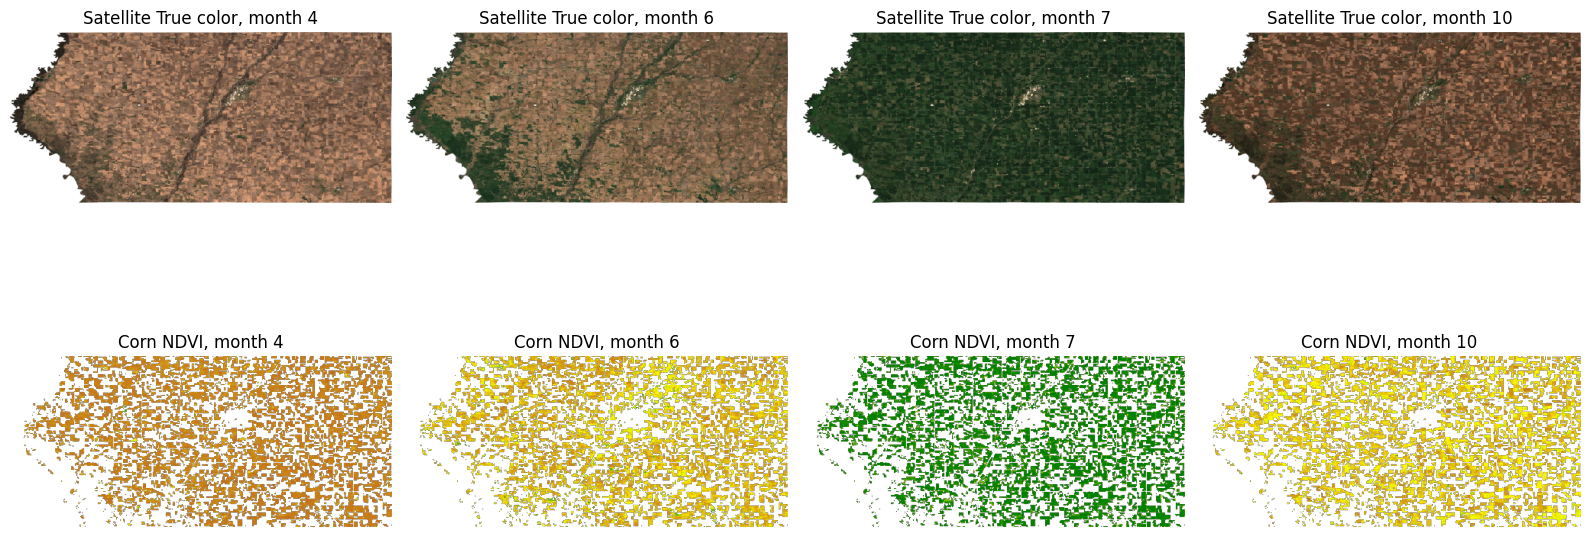

In [11]:
import requests, io
import matplotlib.pyplot as plt
from PIL import Image as PILImage

county = counties.filter(ee.Filter.eq('GEOID', '19149')).first().geometry()
region = county.bounds()
corn = ee.Image('USDA/NASS/CDL/2019').select('cropland').eq(1)

def s2_month(year, month):
    start = ee.Date.fromYMD(year, month, 1)
    return (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
            .filterDate(start, start.advance(1, 'month'))
            .filterBounds(county).map(mask_clouds).median().clip(county))

def fetch(img, vis):
    url = img.getThumbURL({**vis, 'region': region, 'dimensions': 500})
    return PILImage.open(io.BytesIO(requests.get(url).content))

months = [4, 6, 7, 10]        # change to any months from 4 to 10
fig, axes = plt.subplots(2, len(months), figsize=(4 * len(months), 8))
for i, m in enumerate(months):
    s2 = s2_month(2019, m)
    rgb = fetch(s2, {'bands': ['B4', 'B3', 'B2'], 'min': 0, 'max': 3000})
    nd = fetch(s2.normalizedDifference(['B8', 'B4']).updateMask(corn),
               {'min': 0, 'max': 0.9, 'palette': ['brown', 'yellow', 'green']})
    axes[0, i].imshow(rgb); axes[0, i].set_title(f'Satellite True color, month {m}')
    axes[1, i].imshow(nd);  axes[1, i].set_title(f'Corn NDVI, month {m}')
    axes[0, i].axis('off'); axes[1, i].axis('off')
plt.tight_layout(); plt.show()

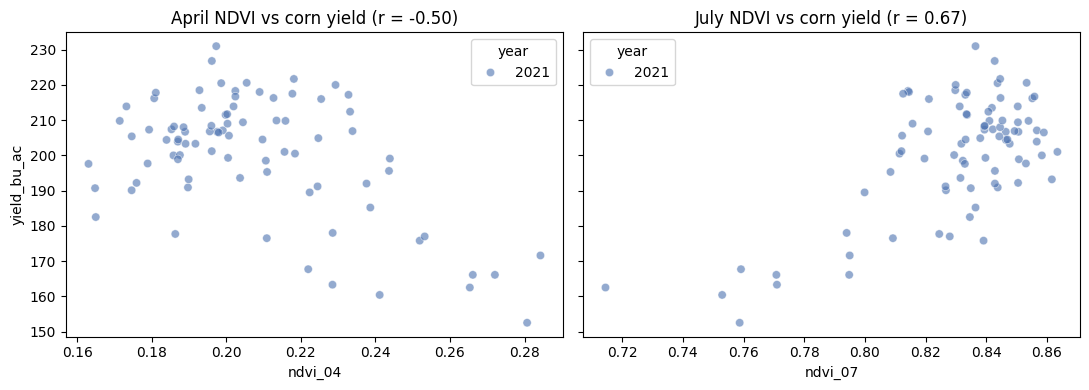

ndvi_04   -0.50
ndvi_05   -0.46
ndvi_06    0.56
ndvi_07    0.67
ndvi_08    0.57
ndvi_09    0.58
ndvi_10    0.00
Name: yield_bu_ac, dtype: float64


In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, col, name in zip(axes, ["ndvi_04", "ndvi_07"], ["April", "July"]):
    r = data[col].corr(data["yield_bu_ac"])
    sns.scatterplot(data=data, x=col, y="yield_bu_ac", hue="year",
                    palette="deep", alpha=.6, ax=ax)
    ax.set_title(f"{name} NDVI vs corn yield (r = {r:.2f})")
plt.tight_layout(); plt.show()

months = [f"ndvi_{m:02d}" for m in range(4, 11)]
print(data[months + ["yield_bu_ac"]].corr()["yield_bu_ac"].drop("yield_bu_ac").round(2))